In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('../data/cleaned_data.csv')
df.head()

,statement,status,clean_statement,mood_category
0,oh my gosh,Anxiety,oh my gosh,A Bit Overwhelmed
1,"trouble sleeping, confused mind, restless hear...",Anxiety,trouble sleeping confused mind restless heart ...,A Bit Overwhelmed
2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,all wrong back off dear forward doubt stay in ...,A Bit Overwhelmed
3,I've shifted my focus to something else but I'...,Anxiety,ive shifted my focus to something else but im ...,A Bit Overwhelmed
4,"I'm restless and restless, it's been a month n...",Anxiety,im restless and restless its been a month now ...,A Bit Overwhelmed


In [4]:
df['clean_statement'].isnull().sum()

np.int64(7)

In [5]:
# Entire dataset se NaN rows drop karne ke liye:
df = df.dropna(subset=['clean_statement'])

In [6]:
df['clean_statement'].isnull().sum()

np.int64(0)

In [7]:
# Feature
X=df['clean_statement']
# Target columns
y=df['mood_category']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (40868,) Test: (10218,)


In [8]:
vectorizer=TfidfVectorizer(max_features=5000,stop_words='english',ngram_range=(1,2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

Accuracy Score 0.7814640829908005
                            precision    recall  f1-score   support

         A Bit Overwhelmed       0.69      0.85      0.76      1184
              Feeling Good       0.88      0.92      0.90      3208
Going Through a Tough Time       0.83      0.66      0.74      3698
          You're not Alone       0.64      0.74      0.69      2128

                  accuracy                           0.78     10218
                 macro avg       0.76      0.79      0.77     10218
              weighted avg       0.79      0.78      0.78     10218



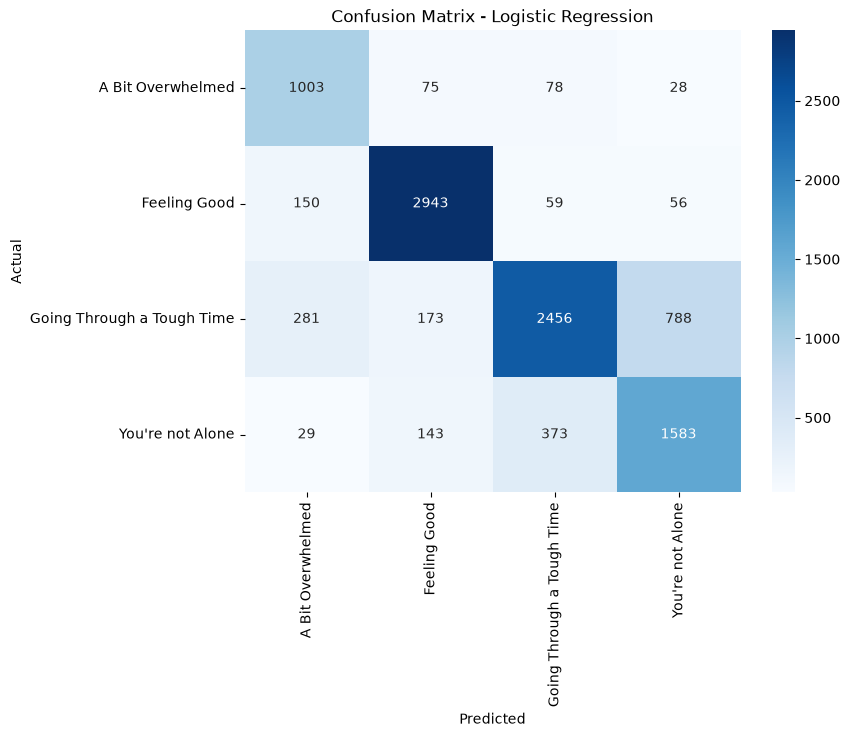

In [22]:
# Logistic Regression Model
log_model=LogisticRegression(max_iter=1000,class_weight='balanced')
log_model.fit(X_train_tfidf,y_train)
y_pred=log_model.predict(X_test_tfidf)
print("Accuracy Score",accuracy_score(y_test,y_pred))
print(classification_report(y_test, y_pred))
# Confusion Matrix
cm=confusion_matrix(y_test,y_pred,labels=log_model.classes_)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',xticklabels=log_model.classes_, yticklabels=log_model.classes_, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [23]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

y_pred_rf = rf_model.predict(X_test_tfidf)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.7679585045997259
                            precision    recall  f1-score   support

         A Bit Overwhelmed       0.70      0.78      0.74      1184
              Feeling Good       0.85      0.92      0.88      3208
Going Through a Tough Time       0.79      0.68      0.73      3698
          You're not Alone       0.65      0.68      0.67      2128

                  accuracy                           0.77     10218
                 macro avg       0.75      0.77      0.75     10218
              weighted avg       0.77      0.77      0.77     10218



In [24]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(class_weight='balanced', max_iter=2000)
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.7767664905069486
                            precision    recall  f1-score   support

         A Bit Overwhelmed       0.71      0.79      0.75      1184
              Feeling Good       0.87      0.92      0.90      3208
Going Through a Tough Time       0.79      0.71      0.75      3698
          You're not Alone       0.65      0.67      0.66      2128

                  accuracy                           0.78     10218
                 macro avg       0.76      0.77      0.76     10218
              weighted avg       0.78      0.78      0.78     10218



In [25]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.6968095517713838
                            precision    recall  f1-score   support

         A Bit Overwhelmed       0.85      0.54      0.66      1184
              Feeling Good       0.84      0.71      0.77      3208
Going Through a Tough Time       0.60      0.81      0.69      3698
          You're not Alone       0.70      0.57      0.63      2128

                  accuracy                           0.70     10218
                 macro avg       0.75      0.66      0.69     10218
              weighted avg       0.72      0.70      0.70     10218



Accuracy: 0.7839107457428068
                            precision    recall  f1-score   support

         A Bit Overwhelmed       0.80      0.76      0.78      1184
              Feeling Good       0.91      0.89      0.90      3208
Going Through a Tough Time       0.76      0.74      0.75      3698
          You're not Alone       0.64      0.72      0.67      2128

                  accuracy                           0.78     10218
                 macro avg       0.78      0.78      0.78     10218
              weighted avg       0.79      0.78      0.79     10218



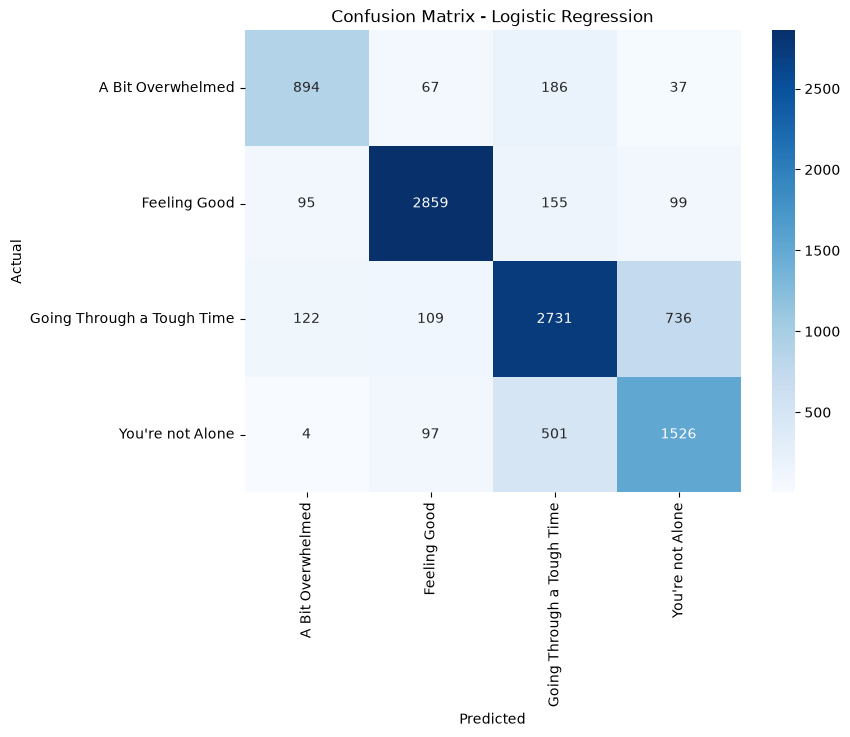

In [26]:
# Final Model
custom_weights = {
    'Feeling Good': 1,
    'A Bit Overwhelmed': 2,
    'Going Through a Tough Time': 2,
    "You're not Alone": 3
}

log_model_v2 = LogisticRegression(max_iter=1000, class_weight=custom_weights)
log_model_v2.fit(X_train_tfidf, y_train)
y_pred_v2 = log_model_v2.predict(X_test_tfidf)
print("Accuracy:", accuracy_score(y_test, y_pred_v2))
print(classification_report(y_test, y_pred_v2))
# Confusion matrix
cm=confusion_matrix(y_test,y_pred_v2,labels=log_model.classes_)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',xticklabels=log_model.classes_, yticklabels=log_model.classes_, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [9]:
from sklearn.utils.class_weight import compute_class_weight
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from scipy.sparse import hstack, csr_matrix

analyzer = SentimentIntensityAnalyzer()
def get_vader_score(text):
    return analyzer.polarity_scores(text)['compound']
X_train_vader = np.array([get_vader_score(t) for t in X_train]).reshape(-1, 1)
X_test_vader = np.array([get_vader_score(t) for t in X_test]).reshape(-1, 1)
X_train_final = hstack([X_train_tfidf, csr_matrix(X_train_vader)])
X_test_final = hstack([X_test_tfidf, csr_matrix(X_test_vader)])

classes=np.unique(y_train)
balanced_weights=compute_class_weight(class_weight='balanced',classes=classes,y=y_train)
weight_dict=dict(zip(classes,balanced_weights))
weight_dict["You're not Alone"]*=1.5
print("final weights",weight_dict)
log_model_v3 = LogisticRegression(max_iter=1000, class_weight=weight_dict)
log_model_v3.fit(X_train_tfidf, y_train)

y_pred_v3 = log_model_v3.predict(X_test_tfidf)
print("Accuracy:", accuracy_score(y_test, y_pred_v3))
print(classification_report(y_test, y_pred_v3))

final weights {'A Bit Overwhelmed': np.float64(2.1577613516367475), 'Feeling Good': np.float64(0.7964608668537574), 'Going Through a Tough Time': np.float64(0.6907111952406706), "You're not Alone": np.float64(1.800246681545871)}
Accuracy: 0.7706009003718928
                            precision    recall  f1-score   support

         A Bit Overwhelmed       0.69      0.84      0.76      1184
              Feeling Good       0.89      0.91      0.90      3208
Going Through a Tough Time       0.85      0.61      0.71      3698
          You're not Alone       0.60      0.81      0.69      2128

                  accuracy                           0.77     10218
                 macro avg       0.76      0.79      0.76     10218
              weighted avg       0.79      0.77      0.77     10218

